# Lag Peak Ablation Analysis

This notebook analyzes a saved `.pt` file from the inference-only lag ablation run on an already trained SNN+CTC model.

It does not retrain or modify the model. It only inspects the saved ablation results to ask whether lag importance around detected CTC evidence peaks looks stable, non-uniform, and meaningful.

In [1]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import numpy as np
import torch

## Config

Set `ABLATION_PATH` manually if you want a specific file. If left as `None`, the notebook will try to find the most recent lag peak ablation `.pt` artifact.

In [ ]:
ABLATION_PATH = '../logs/snn/2026-04-06_12-20-33_991769_snn_pid695282/ctc_evidence/validation_run_0030_lag_peak_ablation_block_00.pt'
MAX_EXAMPLE_PEAKS = 5
MIN_GROUP_SAMPLES = 8
MAX_GROUPS_TO_PLOT = 6
TOP_NB_HEATMAP_LIMIT = 0.25
FIGURES_PDF_PATH = 'lag_peak_ablation_basic_analysis_figures.pdf'


In [3]:
ablation_path = Path(ABLATION_PATH)
if not ablation_path.exists():
    candidate = Path('model_training/evaluate_model') / ablation_path
    if candidate.exists():
        ablation_path = candidate.resolve()
print(f'Using ablation file: {ablation_path}')

Using ablation file: ../logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592/ctc_evidence/validation_run_0008_lag_peak_ablation_block_00.pt


## Load And Inspect Structure

The notebook starts by inspecting keys and value shapes first instead of assuming the artifact matches one exact schema.

In [4]:
def load_artifact(path: Path | str):
    path = Path(path)
    suffix = path.suffix.lower()
    if suffix == '.pt':
        return torch.load(path, map_location='cpu', weights_only=False)
    if suffix == '.pkl':
        with open(path, 'rb') as f:
            return pickle.load(f)
    if suffix == '.npz':
        npz = np.load(path, allow_pickle=True)
        return {key: npz[key] for key in npz.files}
    raise ValueError(f'Unsupported artifact type: {path.suffix}')


def as_numpy(value):
    if value is None:
        return None
    if torch.is_tensor(value):
        return value.detach().cpu().numpy()
    return np.asarray(value)


def summarize_value(name, value, indent=0):
    prefix = '  ' * indent
    if isinstance(value, dict):
        print(f'{prefix}{name}: dict keys={list(value.keys())}')
        return
    if isinstance(value, list):
        print(f'{prefix}{name}: list len={len(value)}')
        if len(value) > 0:
            first = value[0]
            if isinstance(first, dict):
                print(f'{prefix}  first item keys={list(first.keys())}')
            elif torch.is_tensor(first):
                print(f'{prefix}  first item tensor shape={tuple(first.shape)} dtype={first.dtype}')
            elif isinstance(first, np.ndarray):
                print(f'{prefix}  first item ndarray shape={first.shape} dtype={first.dtype}')
            else:
                print(f'{prefix}  first item type={type(first).__name__}')
        return
    if torch.is_tensor(value):
        print(f'{prefix}{name}: tensor shape={tuple(value.shape)} dtype={value.dtype}')
        return
    if isinstance(value, np.ndarray):
        print(f'{prefix}{name}: ndarray shape={value.shape} dtype={value.dtype}')
        return
    print(f'{prefix}{name}: {type(value).__name__} -> {value}')


artifact = load_artifact(ablation_path)
print('Top-level keys:')
for key, value in artifact.items():
    summarize_value(key, value)

metadata = artifact.get('metadata', {})
aggregate = artifact.get('aggregate', {})
peaks = artifact.get('peaks', [])

print('\nMetadata:')
for key, value in metadata.items():
    summarize_value(key, value, indent=1)

print('\nAggregate keys:')
for key, value in aggregate.items():
    summarize_value(key, value, indent=1)

if len(peaks) > 0:
    print('\nFirst peak record:')
    for key, value in peaks[0].items():
        summarize_value(key, value, indent=1)
    lag_results = peaks[0].get('lag_results', [])
    if len(lag_results) > 0:
        print('\nFirst lag result inside first peak:')
        for key, value in lag_results[0].items():
            summarize_value(key, value, indent=2)
else:
    print('\nNo peak records found.')

Top-level keys:
metadata: dict keys=['analysis_type', 'evidence_path', 'block_idx', 'lag_values', 'include_only_lag0', 'ablation_conditions', 'window_radius', 'top_peak_min_prob', 'blank_probability_max', 'min_peak_distance', 'use_saved_peak_indices', 'num_selected_trials', 'num_matched_trials', 'num_peak_records', 'num_detected_peaks', 'num_in_range_peaks', 'num_batches_with_targets', 'evidence_source']
aggregate: dict keys=['mean_by_lag', 'relative_time_by_lag', 'by_predicted_class']
peaks: list len=28868
  first item keys=['trial_id', 'peak_timestep', 'predicted_class_at_peak', 'predicted_phoneme_at_peak', 'baseline_metrics_at_peak', 'argmax_class', 'top_non_blank_class', 'blank_probability', 'top_non_blank_probability', 'entropy', 'baseline_window', 'lag_results']

Metadata:
  analysis_type: str -> lag_peak_ablation
  evidence_path: str -> logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592/ctc_evidence/validation_run_0008.pt
  block_idx: int -> 0
  lag_values: list len=8


In [5]:
mean_by_lag = aggregate.get('mean_by_lag', [])
relative_time_by_lag = aggregate.get('relative_time_by_lag', [])
by_predicted_class = aggregate.get('by_predicted_class', [])

available_lag_indices = sorted({int(item['lag_index']) for item in mean_by_lag}) if mean_by_lag else []
available_lag_values = [int(item.get('lag_value', item['lag_index'])) for item in mean_by_lag] if mean_by_lag else []

num_trials = metadata.get('num_selected_trials', 'unknown')
num_peaks = metadata.get('num_peak_records', len(peaks))

print(f'Number of analyzed trials: {num_trials}')
print(f'Number of detected peaks: {num_peaks}')
print(f'Available lag indices: {available_lag_indices}')
print(f'Available lag values: {available_lag_values}')

main_fields = {
    'per_lag_importance': list(mean_by_lag[0].keys()) if mean_by_lag else None,
    'peak_level_fields': list(peaks[0].keys()) if peaks else None,
    'lag_result_fields': list(peaks[0]['lag_results'][0].keys()) if peaks and peaks[0].get('lag_results') else None,
}
print('\nMain available fields:')
for name, fields in main_fields.items():
    print(f'  {name}: {fields}')

Number of analyzed trials: 1426
Number of detected peaks: 28868
Available lag indices: [0, 1, 2, 3, 4, 5, 6, 7]
Available lag values: [0, 1, 2, 3, 4, 5, 6, 7, 0]

Main available fields:
  per_lag_importance: ['condition_index', 'condition_name', 'lag_index', 'lag_value', 'num_peaks', 'mean_delta_blank_probability', 'mean_delta_top_non_blank_probability', 'mean_delta_entropy', 'mean_logit_l1_diff', 'mean_logit_l2_diff']
  peak_level_fields: ['trial_id', 'peak_timestep', 'predicted_class_at_peak', 'predicted_phoneme_at_peak', 'baseline_metrics_at_peak', 'argmax_class', 'top_non_blank_class', 'blank_probability', 'top_non_blank_probability', 'entropy', 'baseline_window', 'lag_results']
  lag_result_fields: ['condition_index', 'condition_name', 'lag_index', 'lag_value', 'ablated_metrics_at_peak', 'ablated_window', 'importance_window', 'importance_at_peak']


The main quantities of interest are now the decision-sensitivity metrics: per-lag changes in top non-blank probability and blank probability after ablation. Entropy remains useful context, and logit-distance is kept only as a secondary representation-sensitivity diagnostic. If the local window is present, it also lets us ask whether decision damage is strongest exactly at the peak or slightly before or after it.

## Helpers

These helpers keep the notebook short and make missing fields easier to handle gracefully.

In [6]:
if 'figures_pdf' in globals() and figures_pdf is not None:
    try:
        figures_pdf.close()
    except Exception:
        pass
figures_pdf = PdfPages(FIGURES_PDF_PATH)
print(f'Saving figures to: {Path(FIGURES_PDF_PATH).resolve()}')


def save_figure_to_pdf(fig):
    if fig is None:
        return
    figures_pdf.savefig(fig, bbox_inches='tight')


def print_missing(name):
    print(f'[missing] {name} was not found in the saved artifact')


def normalize_phoneme_token(value, phoneme_classes):
    if value is None:
        return None
    if isinstance(value, bytes):
        value = value.decode('utf-8')
    if isinstance(value, str):
        return value
    if isinstance(value, (int, np.integer)):
        idx = int(value)
        if 0 <= idx < len(phoneme_classes):
            return str(phoneme_classes[idx])
        return str(idx)
    if isinstance(value, (float, np.floating)) and float(value).is_integer():
        idx = int(value)
        if 0 <= idx < len(phoneme_classes):
            return str(phoneme_classes[idx])
        return str(idx)
    return str(value)


def resolve_evidence_path(raw_path, ablation_path):
    ablation_path = Path(ablation_path)
    candidates = []

    if raw_path is not None:
        raw_path = Path(raw_path)
        if raw_path.is_absolute():
            candidates.append(raw_path)
        else:
            candidates.append(raw_path)
            candidates.append(Path.cwd() / raw_path)
            candidates.append(ablation_path.parent / raw_path)
            candidates.append(ablation_path.parent.parent / raw_path)
            candidates.append(Path('model_training/evaluate_model') / raw_path)

    if ablation_path.name.endswith('_lag_peak_ablation_block_00.pt'):
        candidates.append(ablation_path.with_name(ablation_path.name.replace('_lag_peak_ablation_block_00.pt', '.pt')))

    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        if candidate.exists():
            return candidate
    return None


def build_targets_by_trial(evidence_payload, phoneme_classes):
    targets_by_trial = {}
    if evidence_payload is None:
        return targets_by_trial

    trials = evidence_payload.get('trials', []) if isinstance(evidence_payload, dict) else []
    for trial in trials:
        trial_id = trial.get('trial_id')
        target_sequence = trial.get('target_sequence')
        if trial_id is None or target_sequence is None:
            continue

        target_array = as_numpy(target_sequence)
        if target_array is None:
            continue
        target_array = np.asarray(target_array)
        if target_array.ndim == 0:
            target_array = target_array.reshape(1)

        normalized = [normalize_phoneme_token(item, phoneme_classes) for item in target_array.tolist()]
        normalized = [item for item in normalized if item is not None]
        if normalized:
            targets_by_trial[trial_id] = normalized

    return targets_by_trial


def label_true_positive_peaks(analysis_records, targets_by_trial, phoneme_classes):
    tp_records = []
    fp_records = []
    missing_trial_ids = []

    for record in analysis_records:
        predicted_phoneme = record.get('predicted_phoneme_at_peak')
        if predicted_phoneme is None:
            predicted_class = record.get('predicted_class_at_peak')
            if predicted_class is not None and 0 <= int(predicted_class) < len(phoneme_classes):
                predicted_phoneme = phoneme_classes[int(predicted_class)]
        record['predicted_phoneme_at_peak'] = predicted_phoneme

        trial_id = record.get('trial_id')
        if trial_id not in targets_by_trial:
            record['is_true_positive'] = False
            missing_trial_ids.append(trial_id)
            continue

        target_sequence = targets_by_trial[trial_id]
        is_true_positive = predicted_phoneme in target_sequence if predicted_phoneme is not None else False
        record['is_true_positive'] = bool(is_true_positive)

        if is_true_positive:
            tp_records.append(record)
        else:
            fp_records.append(record)

    if missing_trial_ids:
        unique_missing = sorted({trial_id for trial_id in missing_trial_ids if trial_id is not None})
        sample = unique_missing[:5]
        print(f'[warn] missing targets for {len(unique_missing)} trial_id(s); skipped from TP/FP split. sample={sample}')

    return analysis_records, tp_records, fp_records


VOWEL_PHONEMES = {
    'AA', 'AE', 'AH', 'AO', 'AW', 'AX', 'AXR', 'AY',
    'EH', 'ER', 'EY', 'IH', 'IX', 'IY', 'OW', 'OY', 'UH', 'UW'
}


def broad_phoneme_category(label):
    if label is None:
        return None
    label = str(label)
    if label in VOWEL_PHONEMES:
        return 'vowels'
    if label in {'BLANK', ' | '}:
        return None
    return 'consonants'


FAST_PHONEMES = {
    'P', 'B', 'T', 'D', 'K', 'G',
    'CH', 'JH',
    'F', 'V', 'TH', 'DH', 'S', 'Z', 'SH', 'ZH', 'HH'
}
SLOW_PHONEMES = {
    'M', 'N', 'NG', 'L', 'R', 'W', 'Y',
    'AA', 'AE', 'AH', 'AO', 'AW', 'AX', 'AXR', 'AY',
    'EH', 'ER', 'EY', 'IH', 'IX', 'IY', 'OW', 'OY', 'UH', 'UW'
}


def fast_slow_phoneme_group(label):
    if label is None:
        return None
    label = str(label)
    if label in FAST_PHONEMES:
        return 'fast / transient'
    if label in SLOW_PHONEMES:
        return 'slow / sustained'
    return None


def current_phoneme_type(peak_record):
    broad = broad_phoneme_category(get_predicted_phoneme_label(peak_record))
    if broad == 'vowels':
        return 'vowel'
    if broad == 'consonants':
        return 'consonant'
    return None


def safe_previous_phoneme_category(peak_record):
    for key in ['previous_phoneme_category', 'previous_phoneme_type']:
        value = peak_record.get(key)
        if value is None:
            continue
        value = str(value).strip().lower()
        if value in {'vowel', 'vowels'}:
            return 'vowel', 'explicit'
        if value in {'consonant', 'consonants'}:
            return 'consonant', 'explicit'

    previous_label = peak_record.get('previous_phoneme_at_peak')
    broad = broad_phoneme_category(previous_label)
    if broad == 'vowels':
        return 'vowel', 'explicit'
    if broad == 'consonants':
        return 'consonant', 'explicit'
    return None, None


def get_predicted_phoneme_label(peak_record):
    label = peak_record.get('predicted_phoneme_at_peak')
    if label is not None:
        return str(label)
    predicted_class = peak_record.get('predicted_class_at_peak')
    if predicted_class is None:
        return None
    if 0 <= int(predicted_class) < len(phoneme_classes):
        return str(phoneme_classes[int(predicted_class)])
    return None


def get_condition_name(lag_result):
    return str(lag_result.get('condition_name', 'single_lag_ablation'))


def make_condition_label(lag_result):
    condition_name = get_condition_name(lag_result)
    lag_value = int(lag_result.get('lag_value', lag_result.get('lag_index', -1)))
    if condition_name == 'only_lag_0':
        return 'only lag 0'
    return f'ablate lag {lag_value}'


def should_include_condition(lag_result, condition_names=None):
    if condition_names is None:
        return True
    return get_condition_name(lag_result) in set(condition_names)


def aggregate_group_peaks(group_peaks, condition_names=('single_lag_ablation',)):
    per_rel = {}
    lag_values = set()

    for peak_record in group_peaks:
        for lag_result in peak_record.get('lag_results', []):
            if not should_include_condition(lag_result, condition_names):
                continue
            lag_idx = int(lag_result.get('lag_index', -1))
            lag_value = int(lag_result.get('lag_value', lag_idx))
            lag_values.add(lag_value)
            importance_window = lag_result.get('importance_window', {})
            rel_offsets = as_numpy(importance_window.get('relative_offsets'))
            delta_top_nb = as_numpy(importance_window.get('delta_top_non_blank_probability'))
            if rel_offsets is None or delta_top_nb is None:
                continue
            rel_offsets = np.asarray(rel_offsets, dtype=int)
            delta_top_nb = np.asarray(delta_top_nb, dtype=float)
            if len(rel_offsets) != len(delta_top_nb):
                continue
            for rel_idx, rel_offset in enumerate(rel_offsets):
                key = (lag_value, int(rel_offset))
                per_rel.setdefault(key, []).append(float(delta_top_nb[rel_idx]))

    return sorted(lag_values), per_rel


def build_group_heatmap_payload(group_peaks, condition_names=('single_lag_ablation',)):
    if not group_peaks:
        return None
    lag_values, per_rel = aggregate_group_peaks(group_peaks, condition_names=condition_names)
    rel_offsets = sorted({rel_offset for (_, rel_offset) in per_rel.keys()})
    if not lag_values or not rel_offsets:
        return None

    grid = np.full((len(lag_values), len(rel_offsets)), np.nan, dtype=float)
    count_grid = np.zeros((len(lag_values), len(rel_offsets)), dtype=int)
    lag_to_i = {lag_value: i for i, lag_value in enumerate(lag_values)}
    rel_to_j = {rel_offset: j for j, rel_offset in enumerate(rel_offsets)}

    for (lag_value, rel_offset), values in per_rel.items():
        i = lag_to_i[lag_value]
        j = rel_to_j[rel_offset]
        if values:
            grid[i, j] = float(np.mean(values))
            count_grid[i, j] = len(values)

    return {
        'lag_values': lag_values,
        'rel_offsets': rel_offsets,
        'grid': grid,
        'counts': count_grid,
        'num_peaks': len(group_peaks),
    }


def plot_top_nb_heatmap(ax, title, heatmap_payload, vmin=None, vmax=None):
    if heatmap_payload is None:
        ax.axis('off')
        ax.text(0.5, 0.5, f'{title}\n[unavailable]', ha='center', va='center', fontsize=10)
        return None

    image = ax.imshow(
        heatmap_payload['grid'],
        aspect='auto',
        cmap='coolwarm',
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_title(f"{title}\n(n={heatmap_payload['num_peaks']})")
    ax.set_xticks(np.arange(len(heatmap_payload['rel_offsets'])))
    ax.set_xticklabels(heatmap_payload['rel_offsets'])
    ax.set_xlabel('Relative time around peak')
    ax.set_yticks(np.arange(len(heatmap_payload['lag_values'])))
    ax.set_yticklabels(heatmap_payload['lag_values'])
    ax.set_ylim(len(heatmap_payload['lag_values']) - 0.5, -0.5)
    ax.set_ylabel('Lag value')
    return image


def collect_group_ctc_probability_traces(group_peaks, condition_names=None):
    baseline_traces = []
    traces_by_condition = {}
    relative_offsets_ref = None

    for peak_record in group_peaks:
        baseline_window = peak_record.get('baseline_window', {})
        rel_offsets = as_numpy(baseline_window.get('relative_offsets'))
        baseline_probs = as_numpy(baseline_window.get('top_non_blank_probability'))
        if rel_offsets is None or baseline_probs is None:
            continue

        rel_offsets = np.asarray(rel_offsets, dtype=int)
        baseline_probs = np.asarray(baseline_probs, dtype=float)
        if len(rel_offsets) != len(baseline_probs):
            continue

        if relative_offsets_ref is None:
            relative_offsets_ref = rel_offsets
        elif len(rel_offsets) != len(relative_offsets_ref) or not np.array_equal(rel_offsets, relative_offsets_ref):
            continue

        baseline_traces.append(baseline_probs)

        for lag_result in peak_record.get('lag_results', []):
            if not should_include_condition(lag_result, condition_names):
                continue
            condition_name = get_condition_name(lag_result)
            lag_value = int(lag_result.get('lag_value', lag_result.get('lag_index', -1)))
            condition_key = (condition_name, lag_value)
            condition_label = make_condition_label(lag_result)
            ablated_window = lag_result.get('ablated_window', {})
            lag_rel_offsets = as_numpy(ablated_window.get('relative_offsets'))
            lag_probs = as_numpy(ablated_window.get('top_non_blank_probability'))
            if lag_rel_offsets is None or lag_probs is None:
                continue

            lag_rel_offsets = np.asarray(lag_rel_offsets, dtype=int)
            lag_probs = np.asarray(lag_probs, dtype=float)
            if len(lag_rel_offsets) != len(lag_probs):
                continue
            if len(lag_rel_offsets) != len(relative_offsets_ref) or not np.array_equal(lag_rel_offsets, relative_offsets_ref):
                continue

            bucket = traces_by_condition.setdefault(condition_key, {'label': condition_label, 'traces': []})
            bucket['traces'].append(lag_probs)

    if not baseline_traces or relative_offsets_ref is None:
        return None

    baseline_stack = np.stack(baseline_traces, axis=0)
    baseline_mean = np.nanmean(baseline_stack, axis=0)
    baseline_std = np.nanstd(baseline_stack, axis=0)

    condition_payloads = []
    for condition_key, payload in sorted(traces_by_condition.items(), key=lambda item: (item[0][0] != 'single_lag_ablation', item[0][1], item[0][0])):
        trace_stack = np.stack(payload['traces'], axis=0)
        condition_payloads.append(
            {
                'condition_name': condition_key[0],
                'lag_value': condition_key[1],
                'label': payload['label'],
                'mean': np.nanmean(trace_stack, axis=0),
                'std': np.nanstd(trace_stack, axis=0),
                'count': len(payload['traces']),
            }
        )

    return {
        'relative_offsets': relative_offsets_ref,
        'baseline_mean': baseline_mean,
        'baseline_std': baseline_std,
        'baseline_count': len(baseline_traces),
        'conditions': condition_payloads,
    }


def _plot_trace_with_band(ax, rel_offsets, mean_trace, std_trace, color, label, linewidth=2.0, alpha=0.18):
    ax.plot(rel_offsets, mean_trace, color=color, linewidth=linewidth, label=label)
    ax.fill_between(rel_offsets, mean_trace - std_trace, mean_trace + std_trace, color=color, alpha=alpha)


def plot_group_ctc_probability_traces(ax, title, trace_payload):
    if trace_payload is None:
        ax.axis('off')
        ax.text(0.5, 0.5, f'{title}\n[unavailable]', ha='center', va='center', fontsize=10)
        return

    rel_offsets = trace_payload['relative_offsets']
    ax.plot(
        rel_offsets,
        trace_payload['baseline_mean'],
        color='black',
        linewidth=2.5,
        label=f"baseline (n={trace_payload['baseline_count']})",
    )

    colors = plt.cm.viridis(np.linspace(0.1, 0.95, max(len(trace_payload['conditions']), 2)))
    for idx, condition in enumerate(trace_payload['conditions']):
        ax.plot(
            rel_offsets,
            condition['mean'],
            color=colors[idx],
            linewidth=1.6,
            alpha=0.9,
            label=f"{condition['label']} (n={condition['count']})",
        )

    ax.axvline(0, color='0.5', linestyle='--', linewidth=1)
    ax.set_title(f"{title}\n(n={trace_payload['baseline_count']})")
    ax.set_xlabel('Relative time around peak')
    ax.set_ylabel('Top non-blank CTC probability')
    ax.grid(alpha=0.25)
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=8)

def plot_selected_group_ctc_probability_traces(ax, title, trace_payload, selected_lags=(1, 7)):
    if trace_payload is None:
        ax.axis('off')
        ax.text(0.5, 0.5, f'{title}\n[unavailable]', ha='center', va='center', fontsize=10)
        return

    rel_offsets = trace_payload['relative_offsets']
    _plot_trace_with_band(
        ax,
        rel_offsets,
        trace_payload['baseline_mean'],
        trace_payload['baseline_std'],
        color='black',
        label=f"baseline (n={trace_payload['baseline_count']})",
        linewidth=2.5,
        alpha=0.12,
    )

    selected_colors = {1: 'tab:orange', 7: 'tab:red'}
    missing_lags = []
    for lag_value in selected_lags:
        condition = None
        for candidate in trace_payload['conditions']:
            if candidate['condition_name'] == 'single_lag_ablation' and int(candidate['lag_value']) == int(lag_value):
                condition = candidate
                break
        if condition is None:
            missing_lags.append(lag_value)
            continue

        _plot_trace_with_band(
            ax,
            rel_offsets,
            condition['mean'],
            condition['std'],
            color=selected_colors.get(lag_value, 'tab:blue'),
            label=f"{condition['label']} (n={condition['count']})",
            linewidth=2.0,
            alpha=0.18,
        )

    if missing_lags:
        ax.text(0.02, 0.02, f'missing lags: {missing_lags}', transform=ax.transAxes, fontsize=8, va='bottom')

    ax.axvline(0, color='0.5', linestyle='--', linewidth=1)
    ax.set_title(f"{title}\n(n={trace_payload['baseline_count']})")
    ax.set_xlabel('Relative time around peak')
    ax.set_ylabel('Top non-blank CTC probability')
    ax.grid(alpha=0.25)
    ax.legend(loc='best', fontsize=8)



def plot_only_lag0_traces(ax, title, trace_payload):
    if trace_payload is None:
        ax.axis('off')
        ax.text(0.5, 0.5, f'{title}\n[unavailable]', ha='center', va='center', fontsize=10)
        return

    rel_offsets = trace_payload['relative_offsets']
    _plot_trace_with_band(
        ax,
        rel_offsets,
        trace_payload['baseline_mean'],
        trace_payload['baseline_std'],
        color='black',
        label=f"baseline (n={trace_payload['baseline_count']})",
        linewidth=2.5,
        alpha=0.12,
    )

    lag0_condition = None
    for condition in trace_payload['conditions']:
        if condition['condition_name'] == 'only_lag_0':
            lag0_condition = condition
            break

    if lag0_condition is None:
        ax.text(0.02, 0.02, 'only_lag_0 unavailable', transform=ax.transAxes, fontsize=8, va='bottom')
    else:
        _plot_trace_with_band(
            ax,
            rel_offsets,
            lag0_condition['mean'],
            lag0_condition['std'],
            color='tab:red',
            label=f"{lag0_condition['label']} (n={lag0_condition['count']})",
            linewidth=2.0,
            alpha=0.18,
        )

    ax.axvline(0, color='0.5', linestyle='--', linewidth=1)
    ax.set_title(f"{title}\n(n={trace_payload['baseline_count']})")
    ax.set_xlabel('Relative time around peak')
    ax.set_ylabel('Top non-blank CTC probability')
    ax.grid(alpha=0.25)
    ax.legend(loc='best', fontsize=8)


def select_top_phoneme_groups(records, per_category_limit):
    phoneme_groups = {}
    for peak_record in records:
        phoneme_label = get_predicted_phoneme_label(peak_record)
        if phoneme_label is None:
            continue
        phoneme_groups.setdefault(str(phoneme_label), []).append(peak_record)

    ranked_phonemes = sorted(phoneme_groups.items(), key=lambda item: len(item[1]), reverse=True)
    selected = {'vowels': [], 'consonants': []}

    for phoneme_label, group_peaks in ranked_phonemes:
        category = broad_phoneme_category(phoneme_label)
        if category not in selected:
            continue
        if len(group_peaks) < MIN_GROUP_SAMPLES:
            continue
        if len(selected[category]) >= per_category_limit:
            continue
        selected[category].append((phoneme_label, group_peaks))

    return selected


Saving figures to: /home/alex/snn_for_bts/brain_to_text/model_training/evaluate_model/lag_peak_ablation_basic_analysis_figures.pdf


## TP / FP Peak Labeling

A peak is labeled true positive when its predicted phoneme appears anywhere in that trial's ground-truth target sequence. Missing trial targets are warned about and skipped from the TP/FP split.


In [7]:
phoneme_classes = metadata.get('phoneme_classes')
if phoneme_classes is None:
    evidence_path = resolve_evidence_path(metadata.get('evidence_path'), ablation_path)
    evidence_payload = load_artifact(evidence_path) if evidence_path is not None else None
    phoneme_classes = evidence_payload.get('phoneme_classes', []) if isinstance(evidence_payload, dict) else []
else:
    evidence_path = resolve_evidence_path(metadata.get('evidence_path'), ablation_path)
    evidence_payload = load_artifact(evidence_path) if evidence_path is not None else None

if not phoneme_classes:
    phoneme_classes = list(getattr(globals().get('LOGIT_TO_PHONEME', []), 'copy', lambda: [])())

print(f'Resolved evidence path: {evidence_path}')
if evidence_payload is None:
    print('[warn] could not load the source CTC evidence file; TP/FP labeling will be empty')
    targets_by_trial = {}
else:
    targets_by_trial = build_targets_by_trial(evidence_payload, phoneme_classes)
    trial_count = len(evidence_payload.get('trials', [])) if isinstance(evidence_payload, dict) else 0
    print(f'Loaded evidence trials: {trial_count}')
    if trial_count > 0:
        sample_trial = evidence_payload['trials'][0]
        print(f"Sample evidence trial_id: {sample_trial.get('trial_id')}")
        print(f"Sample target_sequence: {sample_trial.get('target_sequence')}")

peaks, tp_peaks, fp_peaks = label_true_positive_peaks(peaks, targets_by_trial, phoneme_classes)

print(f'Targets available for {len(targets_by_trial)} trials')
print(f'Total peaks: {len(peaks)}')
print(f'True positives: {len(tp_peaks)}')
print(f'False positives: {len(fp_peaks)}')


Resolved evidence path: /home/alex/snn_for_bts/brain_to_text/model_training/logs/snn/2026-04-05/2026-04-05_23-15-25_453530_snn_pid574592/ctc_evidence/validation_run_0008.pt
Loaded evidence trials: 1426
Sample evidence trial_id: day_01_block_0008_trial_0000
Sample target_sequence: [37 34 40 20  2 23 40 29 18 40 10  3 40 20 25  9 40  2 31 40 10 17 29 40
 27 26 23 31 40  2 38 40 36 11 21 40]
Targets available for 1426 trials
Total peaks: 28868
True positives: 25447
False positives: 3421


## TP-Only Heatmaps

All heatmaps below use only true-positive peaks and only the top non-blank decision-sensitivity metric.


## TP Summary Heatmap Grid

This compact comparison figure keeps the most useful top non-blank heatmaps: broad vowel/consonant groups, top individual vowel and consonant examples, fast-vs-slow grouping, and previous-to-current vowel/consonant transitions.


Summary heatmap panels:
  Vowels: 6438 peaks (ok)
  AH: 1421 peaks (ok)
  IH: 1132 peaks (ok)
  Consonants: 9769 peaks (ok)
  T: 1273 peaks (ok)
  S: 929 peaks (ok)
  Fast / transient: 6145 peaks (ok)
  Slow / sustained: 10062 peaks (ok)
  Prev vowel -> curr consonant: 4206 peaks (ok)
  Prev consonant -> curr vowel: 5983 peaks (ok)
  Prev vowel -> curr vowel: 154 peaks (ok)
  Prev consonant -> curr consonant: 4951 peaks (ok)


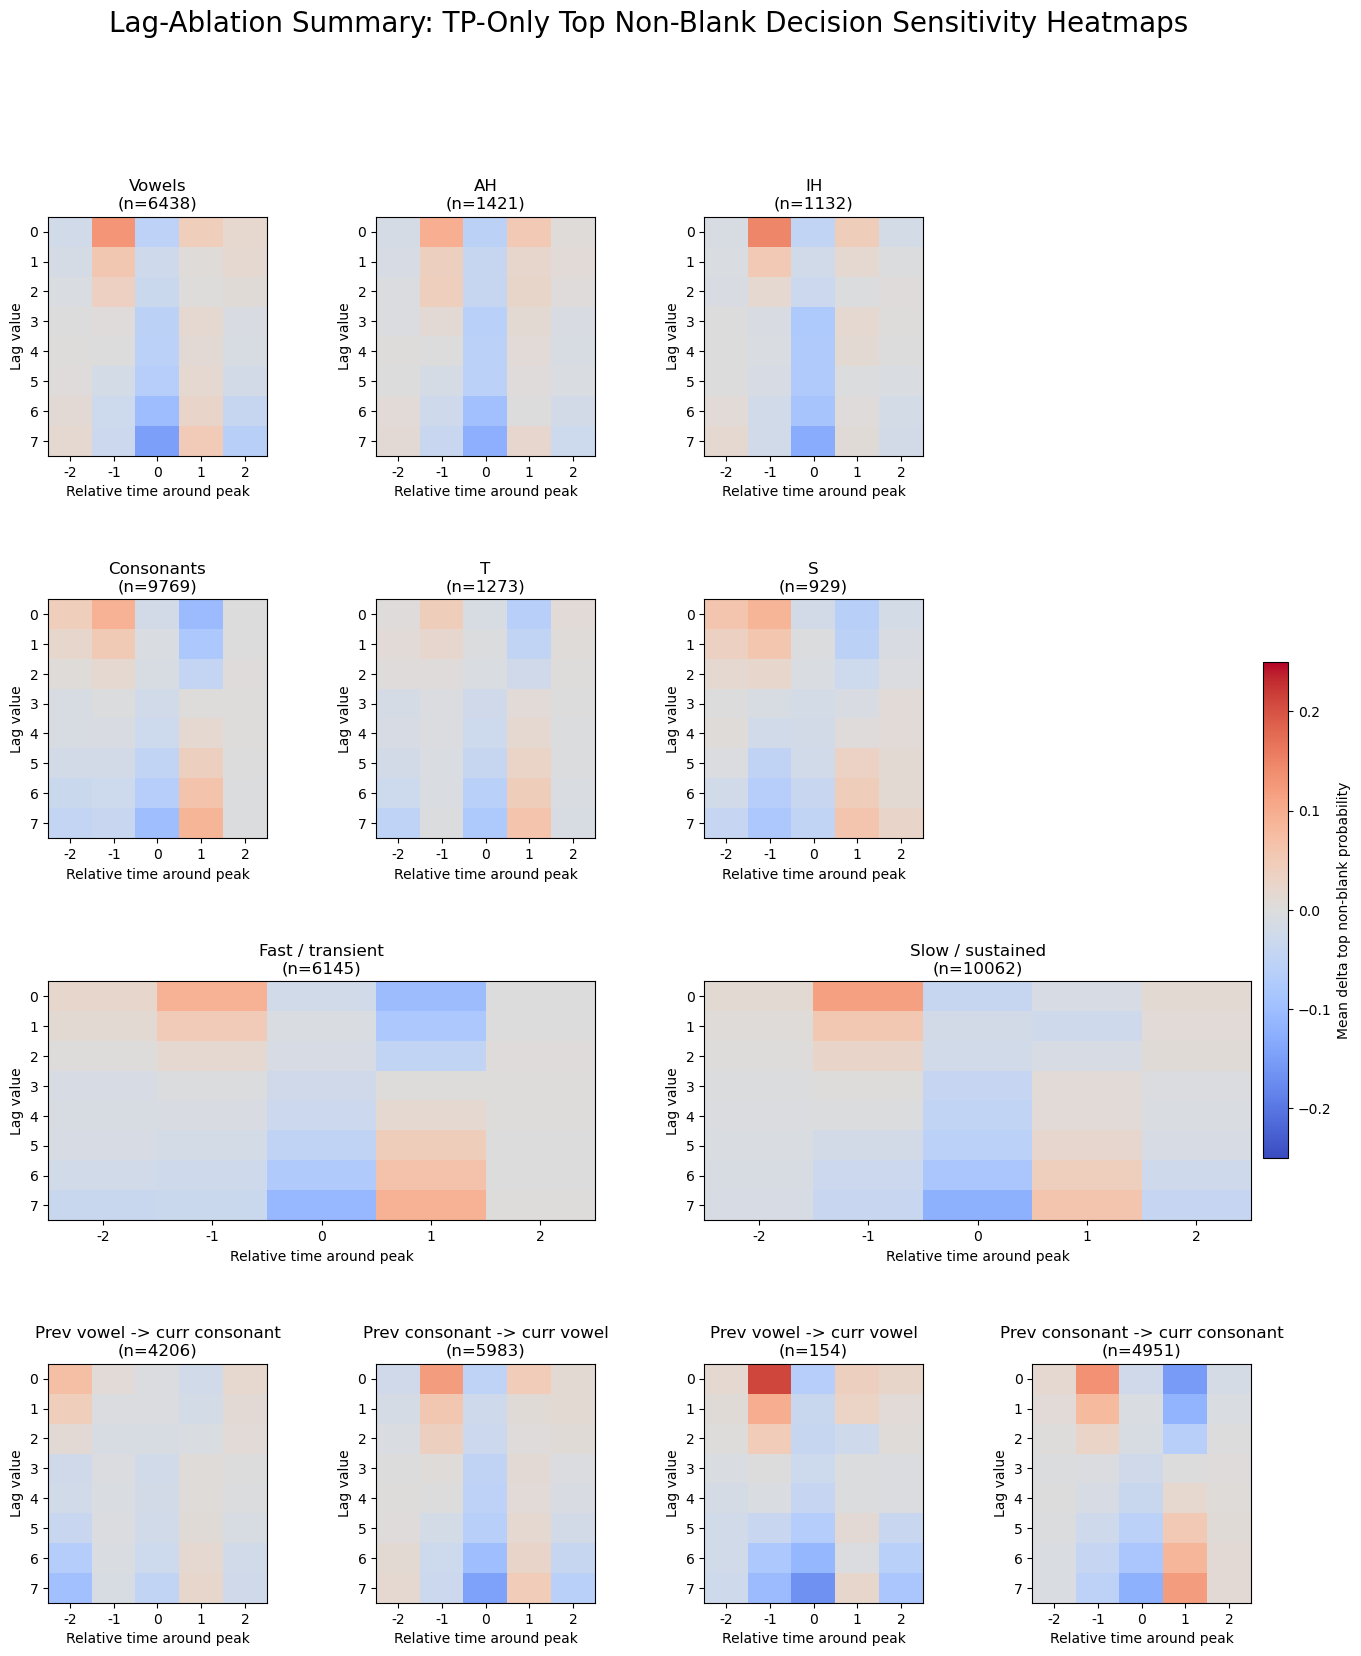

In [8]:
if not tp_peaks:
    print('[skip] no true-positive peaks were available for the summary heatmap grid')
else:
    broad_groups = {'vowels': [], 'consonants': []}
    phoneme_groups = {}
    fast_slow_groups = {'fast / transient': [], 'slow / sustained': []}
    previous_pair_groups = {
        'previous vowel -> current consonant': [],
        'previous consonant -> current vowel': [],
        'previous vowel -> current vowel': [],
        'previous consonant -> current consonant': [],
    }

    for peak_record in tp_peaks:
        predicted_label = get_predicted_phoneme_label(peak_record)
        broad_label = broad_phoneme_category(predicted_label)
        if broad_label in broad_groups:
            broad_groups[broad_label].append(peak_record)
        if predicted_label is not None:
            phoneme_groups.setdefault(str(predicted_label), []).append(peak_record)

        fast_slow_label = fast_slow_phoneme_group(predicted_label)
        if fast_slow_label in fast_slow_groups:
            fast_slow_groups[fast_slow_label].append(peak_record)

        prev_type, _ = safe_previous_phoneme_category(peak_record)
        curr_type = current_phoneme_type(peak_record)
        if prev_type is not None and curr_type is not None:
            pair_key = f'previous {prev_type} -> current {curr_type}'
            if pair_key in previous_pair_groups:
                previous_pair_groups[pair_key].append(peak_record)

    top_vowel_examples = []
    top_consonant_examples = []
    ranked_phonemes = sorted(phoneme_groups.items(), key=lambda item: len(item[1]), reverse=True)
    for phoneme_label, group_peaks in ranked_phonemes:
        broad_label = broad_phoneme_category(phoneme_label)
        if broad_label == 'vowels' and len(group_peaks) >= MIN_GROUP_SAMPLES and len(top_vowel_examples) < 2:
            top_vowel_examples.append((phoneme_label, group_peaks))
        if broad_label == 'consonants' and len(group_peaks) >= MIN_GROUP_SAMPLES and len(top_consonant_examples) < 2:
            top_consonant_examples.append((phoneme_label, group_peaks))
        if len(top_vowel_examples) >= 2 and len(top_consonant_examples) >= 2:
            break

    summary_specs = [
        ('Vowels', broad_groups['vowels'] if len(broad_groups['vowels']) >= MIN_GROUP_SAMPLES else None),
        (top_vowel_examples[0][0], top_vowel_examples[0][1] if len(top_vowel_examples) >= 1 else None),
        (top_vowel_examples[1][0], top_vowel_examples[1][1] if len(top_vowel_examples) >= 2 else None),
        ('Consonants', broad_groups['consonants'] if len(broad_groups['consonants']) >= MIN_GROUP_SAMPLES else None),
        (top_consonant_examples[0][0], top_consonant_examples[0][1] if len(top_consonant_examples) >= 1 else None),
        (top_consonant_examples[1][0], top_consonant_examples[1][1] if len(top_consonant_examples) >= 2 else None),
        ('Fast / transient', fast_slow_groups['fast / transient'] if len(fast_slow_groups['fast / transient']) >= MIN_GROUP_SAMPLES else None),
        ('Slow / sustained', fast_slow_groups['slow / sustained'] if len(fast_slow_groups['slow / sustained']) >= MIN_GROUP_SAMPLES else None),
        ('Prev vowel -> curr consonant', previous_pair_groups['previous vowel -> current consonant'] if len(previous_pair_groups['previous vowel -> current consonant']) >= MIN_GROUP_SAMPLES else None),
        ('Prev consonant -> curr vowel', previous_pair_groups['previous consonant -> current vowel'] if len(previous_pair_groups['previous consonant -> current vowel']) >= MIN_GROUP_SAMPLES else None),
        ('Prev vowel -> curr vowel', previous_pair_groups['previous vowel -> current vowel'] if len(previous_pair_groups['previous vowel -> current vowel']) >= MIN_GROUP_SAMPLES else None),
        ('Prev consonant -> curr consonant', previous_pair_groups['previous consonant -> current consonant'] if len(previous_pair_groups['previous consonant -> current consonant']) >= MIN_GROUP_SAMPLES else None),
    ]

    print('Summary heatmap panels:')
    for title, group_peaks in summary_specs:
        count = len(group_peaks) if group_peaks is not None else 0
        status = 'ok' if group_peaks is not None else 'missing / too few samples'
        print(f'  {title}: {count} peaks ({status})')

    fig = plt.figure(figsize=(16, 18))
    grid = fig.add_gridspec(4, 4, hspace=0.6, wspace=0.5)
    panel_positions = {
        0: grid[0, 0],
        1: grid[0, 1],
        2: grid[0, 2],
        3: grid[1, 0],
        4: grid[1, 1],
        5: grid[1, 2],
        6: grid[2, 0:2],
        7: grid[2, 2:4],
        8: grid[3, 0],
        9: grid[3, 1],
        10: grid[3, 2],
        11: grid[3, 3],
    }

    vmin, vmax = -TOP_NB_HEATMAP_LIMIT, TOP_NB_HEATMAP_LIMIT
    color_image = None
    for idx, (title, group_peaks) in enumerate(summary_specs):
        ax = fig.add_subplot(panel_positions[idx])
        heatmap_payload = build_group_heatmap_payload(group_peaks) if group_peaks is not None else None
        image = plot_top_nb_heatmap(ax, title, heatmap_payload, vmin=vmin, vmax=vmax)
        if color_image is None and image is not None:
            color_image = image

    if color_image is not None:
        cbar = fig.colorbar(color_image, ax=fig.axes, fraction=0.02, pad=0.01)
        cbar.set_label('Mean delta top non-blank probability')

    fig.suptitle('Lag-Ablation Summary: TP-Only Top Non-Blank Decision Sensitivity Heatmaps', fontsize=20, y=0.995)
    save_figure_to_pdf(fig)
    plt.show()


/tmp/ipykernel_656922/1141656142.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


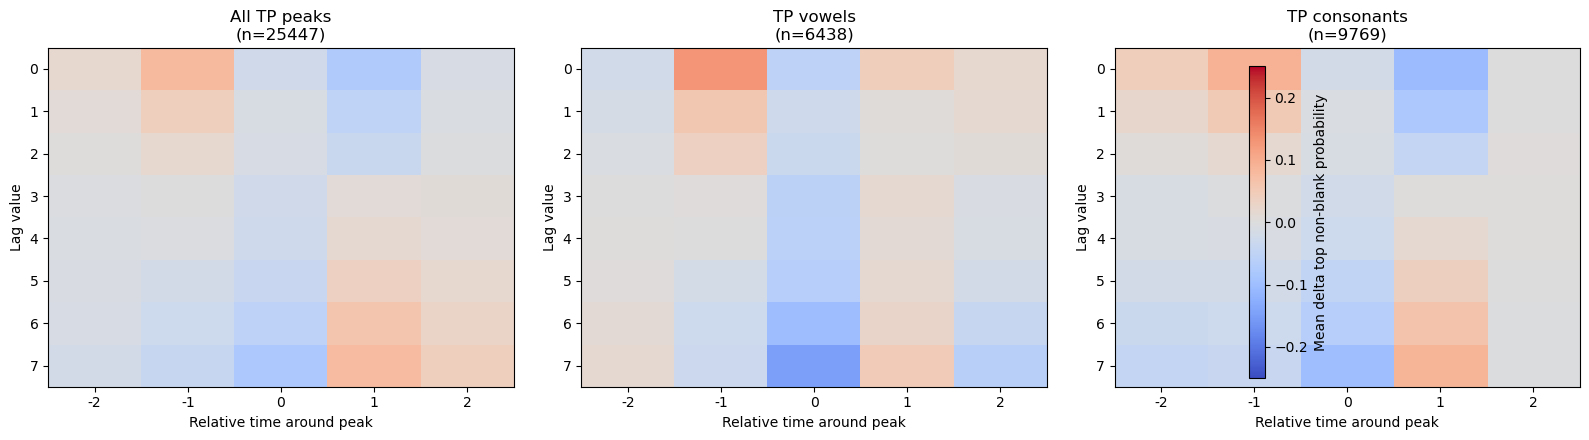

In [9]:
if not tp_peaks:
    print('[skip] no true-positive peaks were available for TP-only heatmaps')
else:
    global_payload = build_group_heatmap_payload(tp_peaks)
    broad_groups = {'vowels': [], 'consonants': []}
    for peak_record in tp_peaks:
        broad_label = broad_phoneme_category(get_predicted_phoneme_label(peak_record))
        if broad_label in broad_groups:
            broad_groups[broad_label].append(peak_record)

    vowel_payload = build_group_heatmap_payload(broad_groups['vowels']) if len(broad_groups['vowels']) >= MIN_GROUP_SAMPLES else None
    consonant_payload = build_group_heatmap_payload(broad_groups['consonants']) if len(broad_groups['consonants']) >= MIN_GROUP_SAMPLES else None

    vmin, vmax = -TOP_NB_HEATMAP_LIMIT, TOP_NB_HEATMAP_LIMIT
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    im = plot_top_nb_heatmap(axes[0], 'All TP peaks', global_payload, vmin=vmin, vmax=vmax)
    plot_top_nb_heatmap(axes[1], 'TP vowels', vowel_payload, vmin=vmin, vmax=vmax)
    plot_top_nb_heatmap(axes[2], 'TP consonants', consonant_payload, vmin=vmin, vmax=vmax)
    if im is not None:
        plt.colorbar(im, ax=axes, label='Mean delta top non-blank probability', shrink=0.9)
    plt.tight_layout()
    save_figure_to_pdf(fig)
    plt.show()


## TP Broad-Group Traces

These traces show baseline top non-blank CTC probability around the peak together with every lag ablation, using only true-positive peaks.


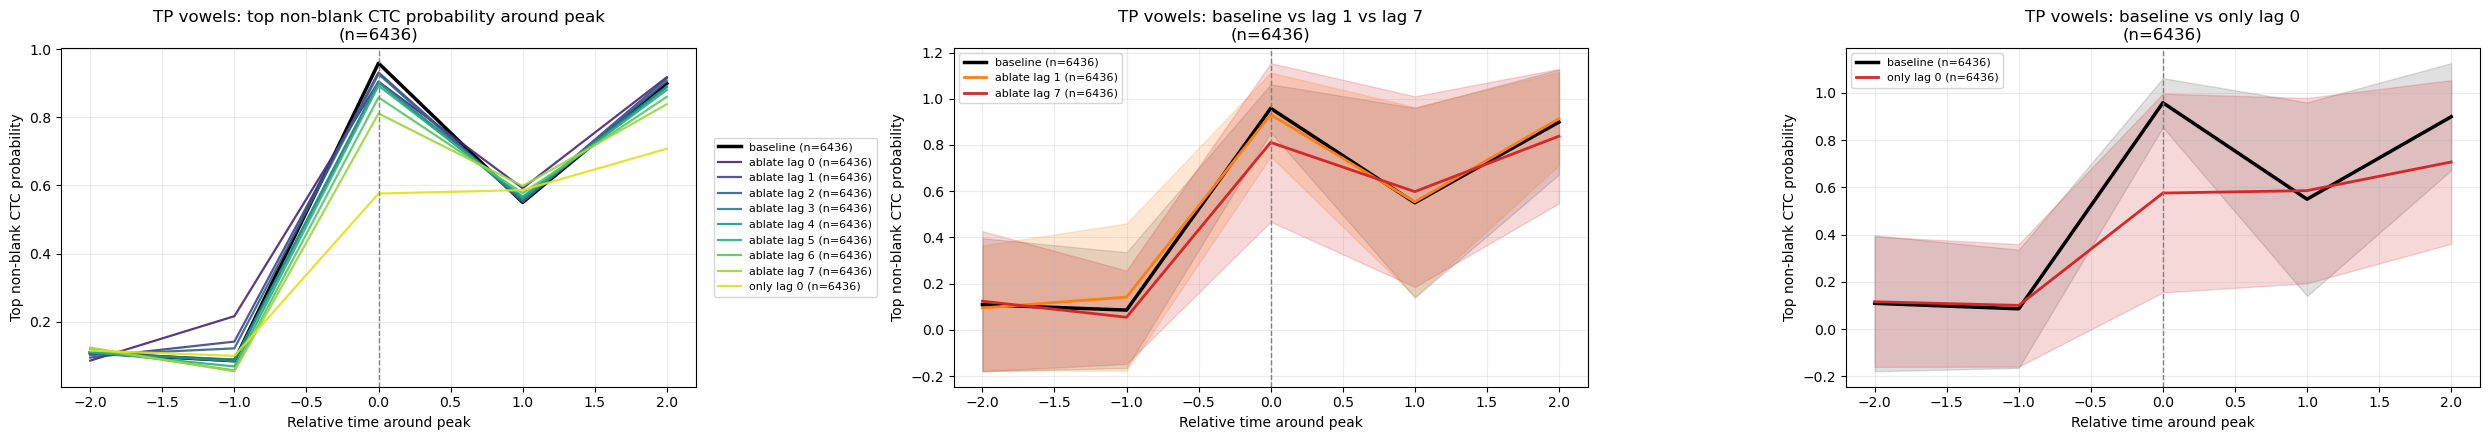

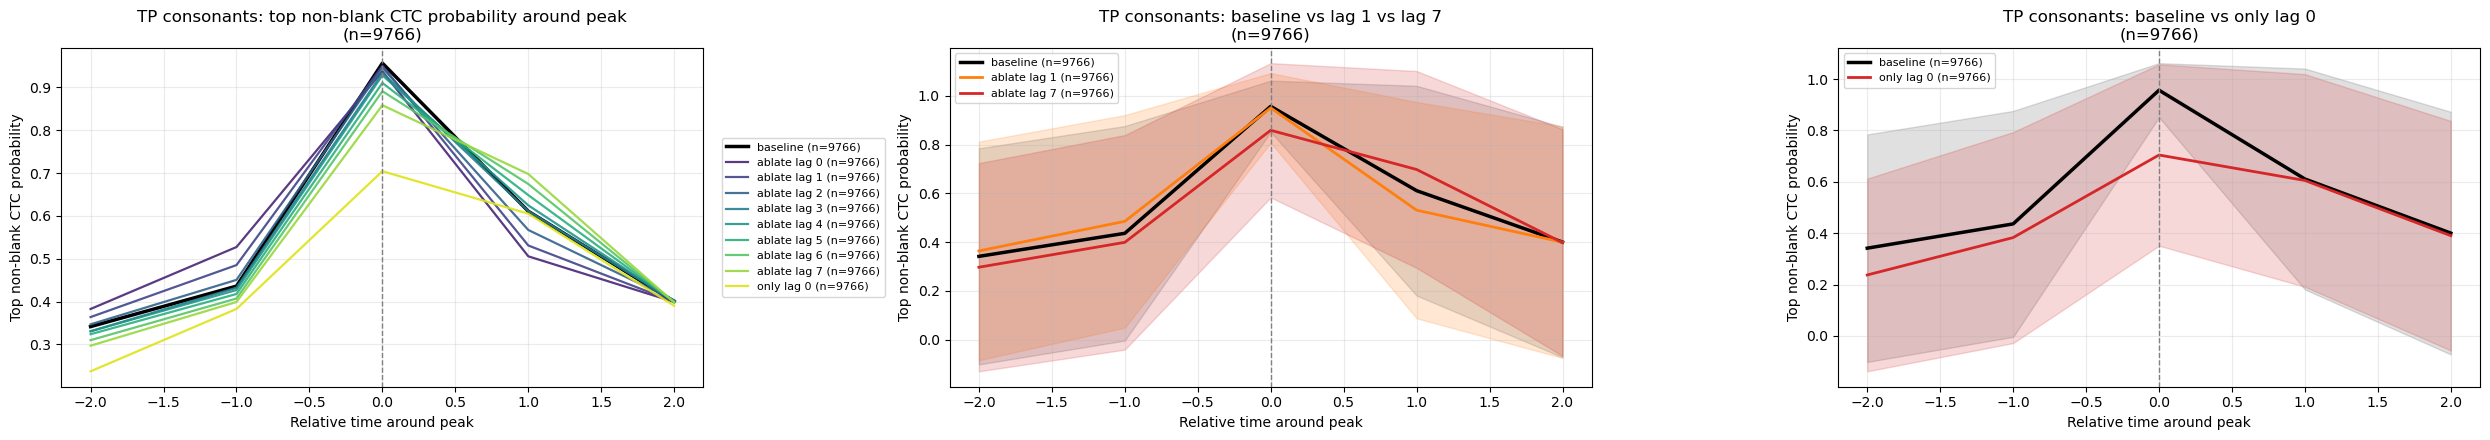

In [10]:
if not tp_peaks:
    print('[skip] no true-positive peaks were available for TP broad-group traces')
else:
    broad_groups = {'vowels': [], 'consonants': []}
    for peak_record in tp_peaks:
        broad_label = broad_phoneme_category(get_predicted_phoneme_label(peak_record))
        if broad_label in broad_groups:
            broad_groups[broad_label].append(peak_record)

    for broad_label in ['vowels', 'consonants']:
        group_peaks = broad_groups[broad_label]
        if len(group_peaks) < MIN_GROUP_SAMPLES:
            print(f'[skip] {broad_label} has only {len(group_peaks)} TP peaks; need at least {MIN_GROUP_SAMPLES}')
            continue
        trace_payload = collect_group_ctc_probability_traces(group_peaks)
        fig, axes = plt.subplots(1, 3, figsize=(25, 4.5))
        plot_group_ctc_probability_traces(
            axes[0],
            title=f"TP {broad_label}: top non-blank CTC probability around peak",
            trace_payload=trace_payload,
        )
        plot_selected_group_ctc_probability_traces(
            axes[1],
            title=f"TP {broad_label}: baseline vs lag 1 vs lag 7",
            trace_payload=trace_payload,
        )
        plot_only_lag0_traces(
            axes[2],
            title=f"TP {broad_label}: baseline vs only lag 0",
            trace_payload=trace_payload,
        )
        plt.tight_layout()
        save_figure_to_pdf(fig)
        plt.show()


## TP Individual Vowel And Consonant Traces

These panels focus on several individual phonemes from the true-positive set, split across vowels and consonants.


Selected TP phoneme trace groups:
  vowels: AH (n=1421)
  vowels: IH (n=1132)
  vowels: IY (n=707)
  consonants: T (n=1273)
  consonants: S (n=929)
  consonants: DH (n=903)


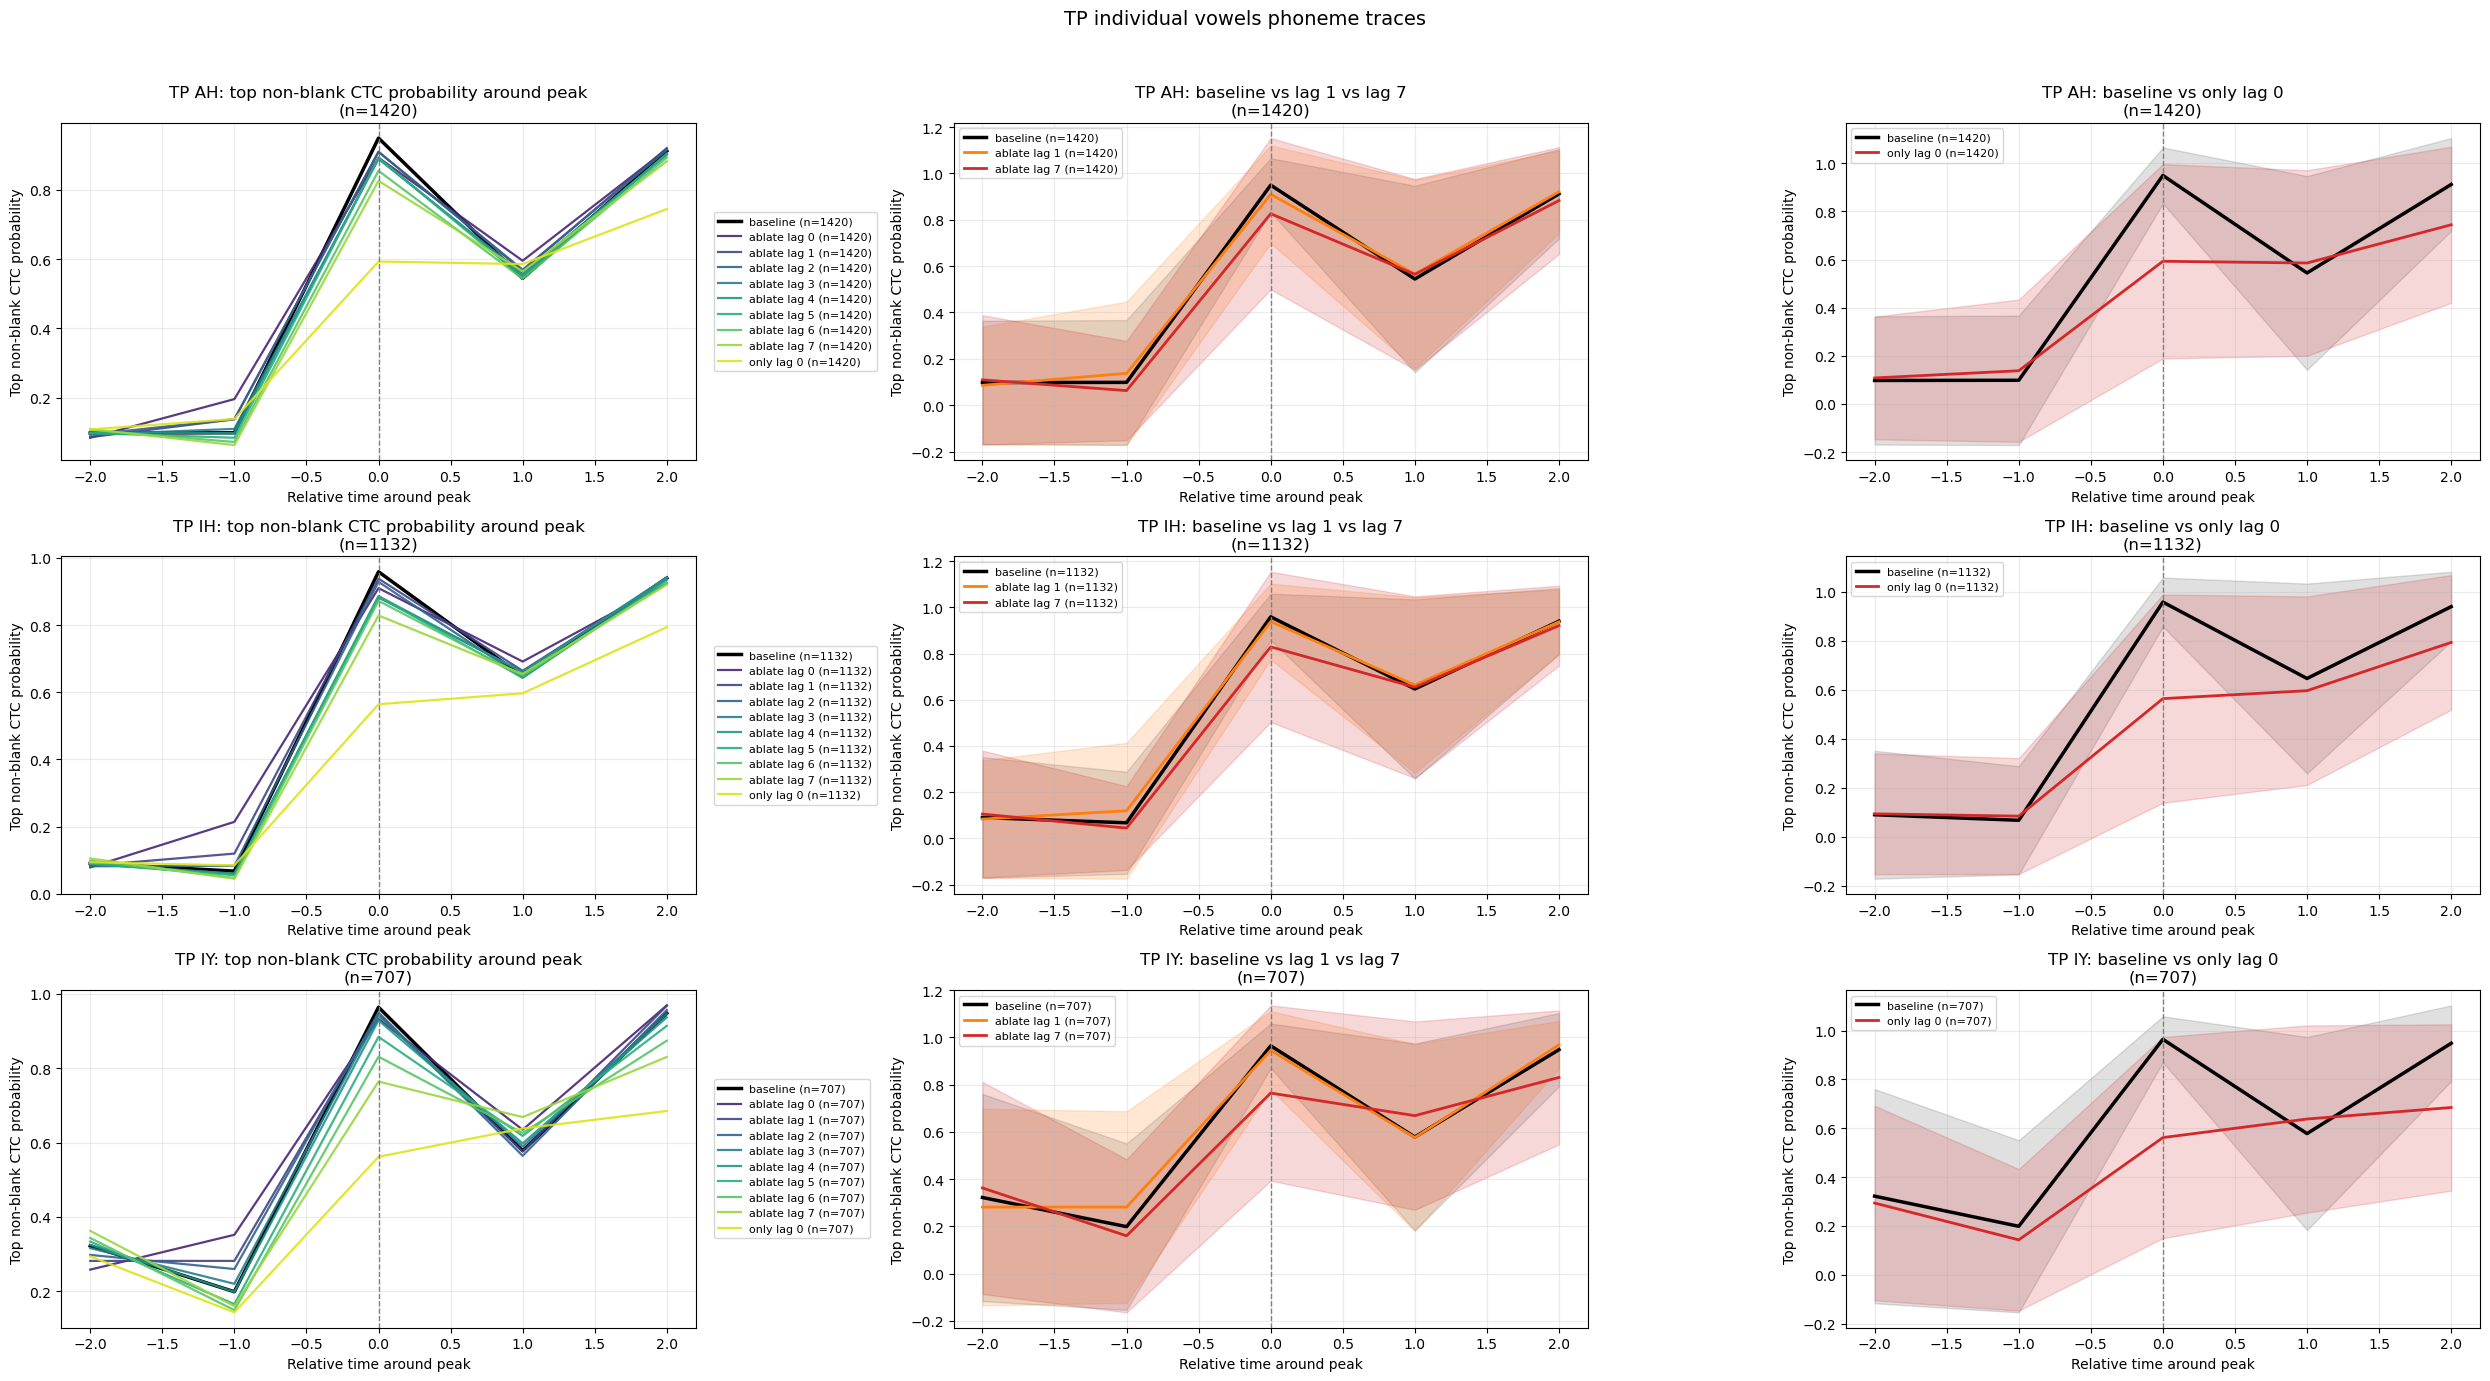

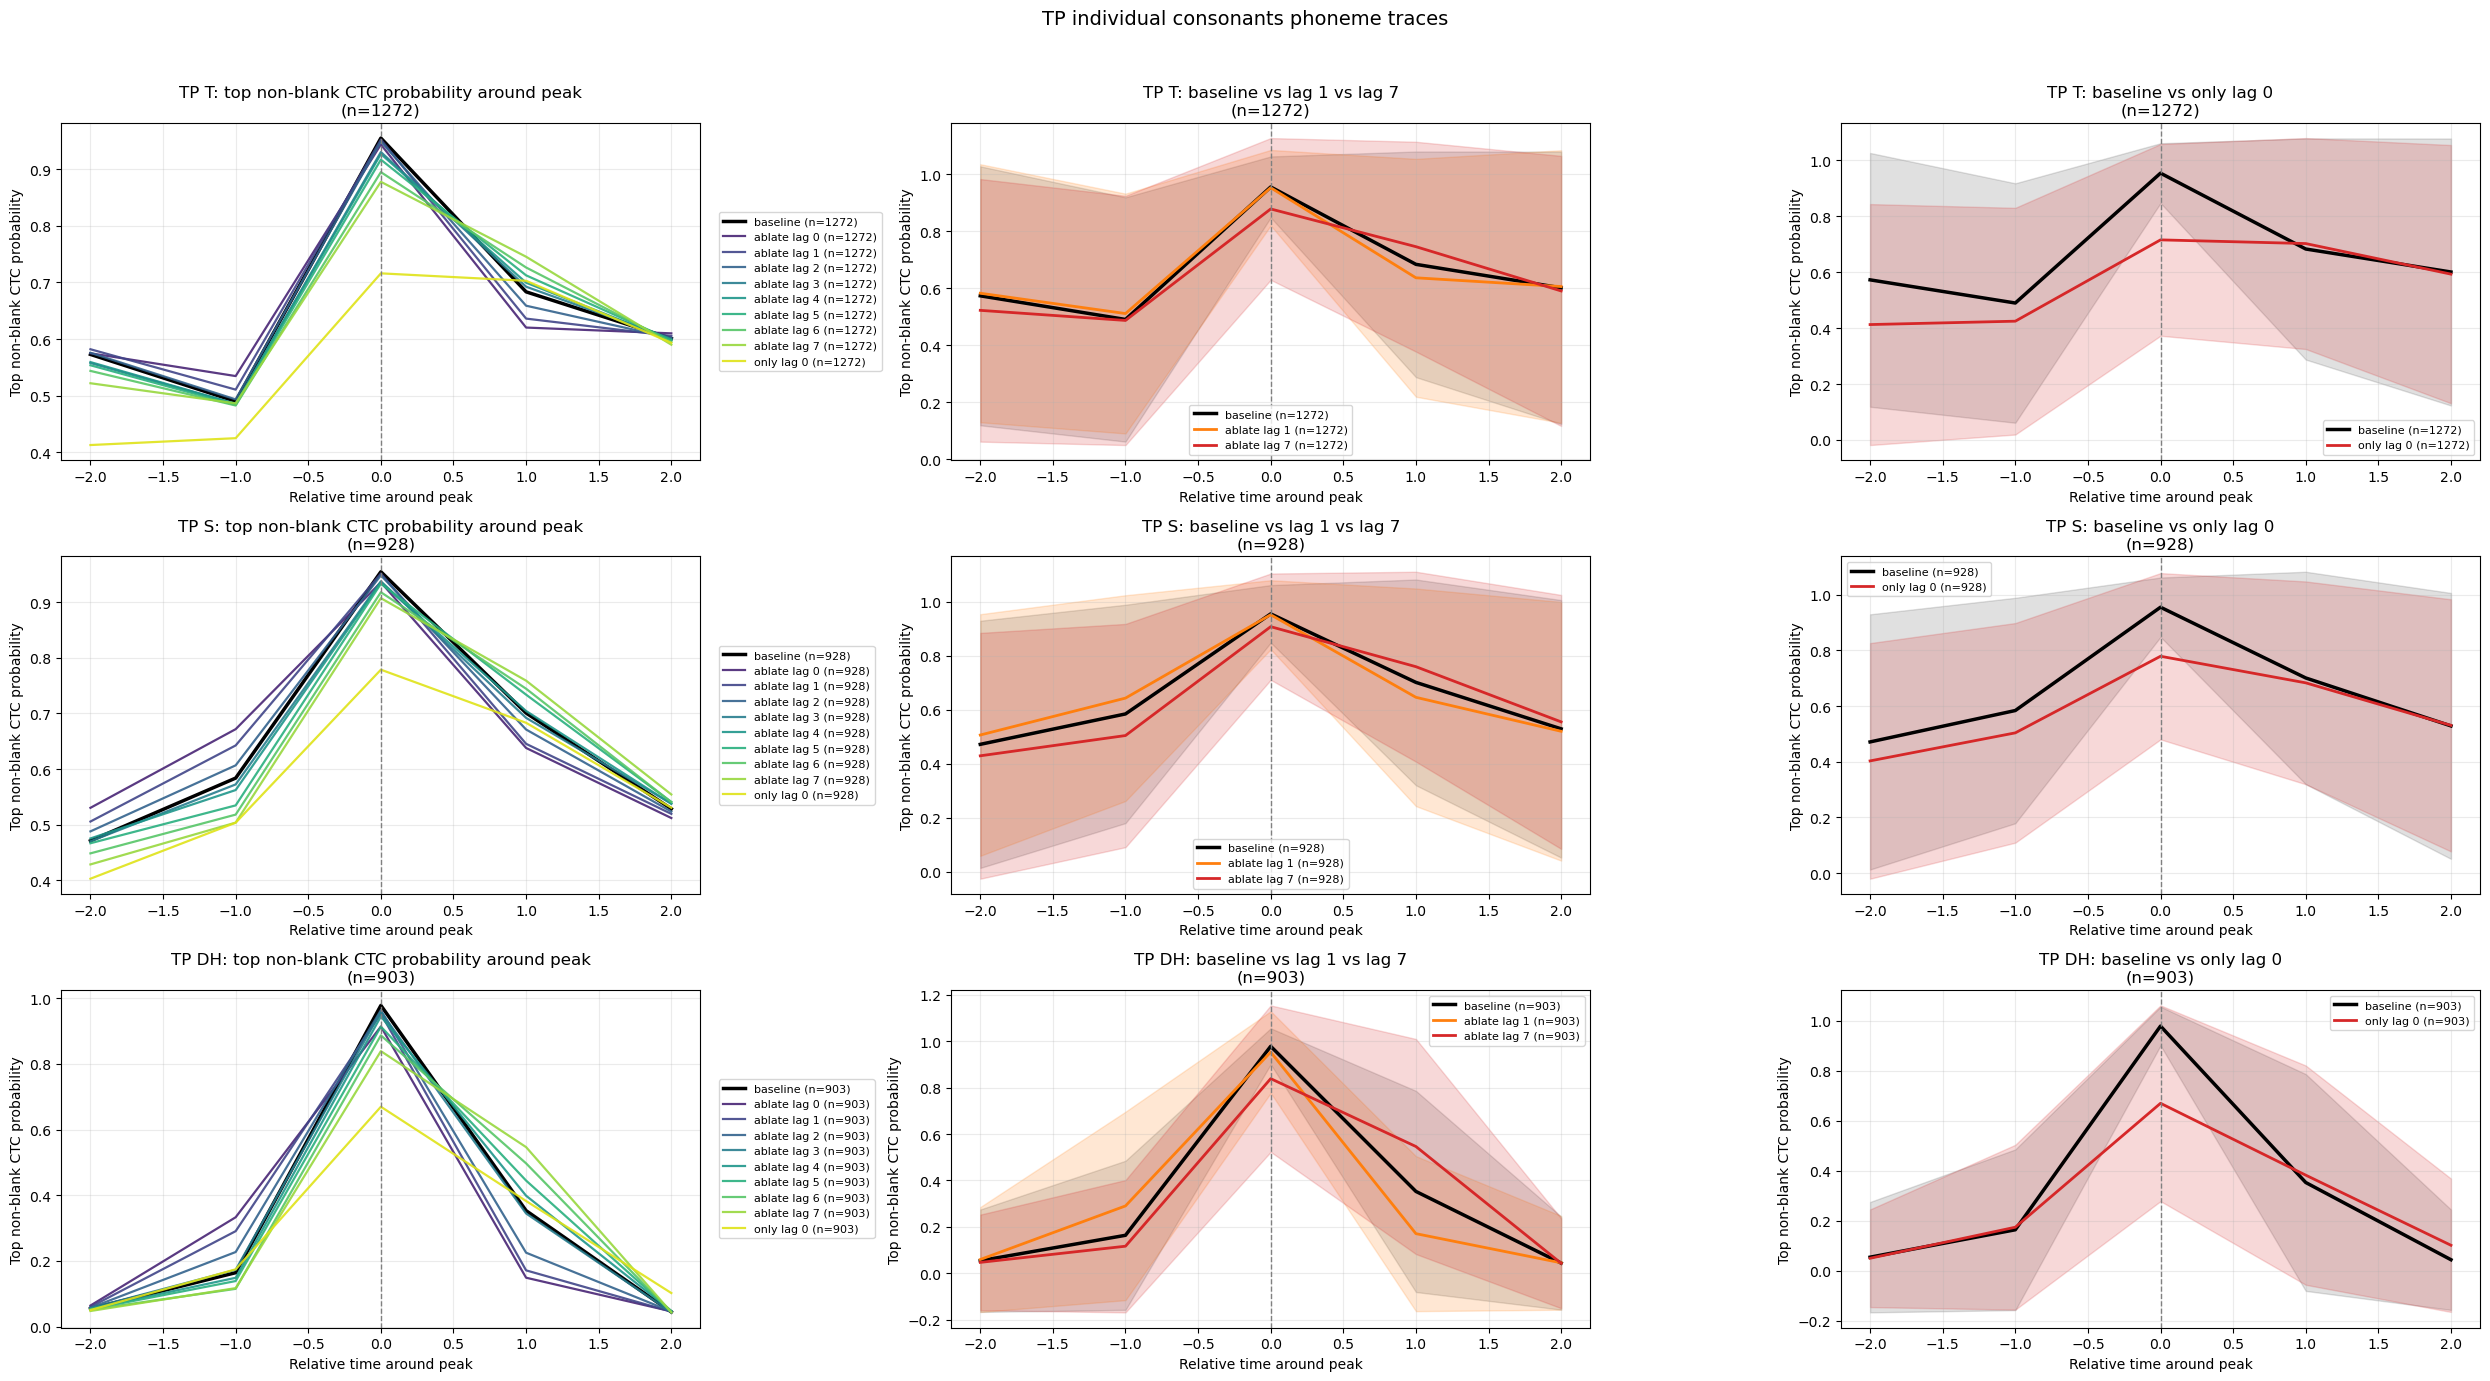

In [11]:
if not tp_peaks:
    print('[skip] no true-positive peaks were available for individual TP phoneme traces')
else:
    selected_by_category = select_top_phoneme_groups(tp_peaks, per_category_limit=max(1, MAX_GROUPS_TO_PLOT // 2))
    total_selected = sum(len(items) for items in selected_by_category.values())

    if total_selected == 0:
        print('[skip] no individual TP phoneme groups passed the minimum sample threshold')
    else:
        print('Selected TP phoneme trace groups:')
        for category in ['vowels', 'consonants']:
            if not selected_by_category[category]:
                print(f'  [skip] {category}: no phonemes met the threshold')
                continue
            for phoneme_label, group_peaks in selected_by_category[category]:
                print(f'  {category}: {phoneme_label} (n={len(group_peaks)})')

        for category in ['vowels', 'consonants']:
            entries = selected_by_category[category]
            if not entries:
                continue
            fig, axes = plt.subplots(len(entries), 3, figsize=(25, 4.5 * len(entries)), squeeze=False)
            for row_idx, (phoneme_label, group_peaks) in enumerate(entries):
                trace_payload = collect_group_ctc_probability_traces(group_peaks)
                plot_group_ctc_probability_traces(
                    axes[row_idx, 0],
                    title=f"TP {phoneme_label}: top non-blank CTC probability around peak",
                    trace_payload=trace_payload,
                )
                plot_selected_group_ctc_probability_traces(
                    axes[row_idx, 1],
                    title=f"TP {phoneme_label}: baseline vs lag 1 vs lag 7",
                    trace_payload=trace_payload,
                )
                plot_only_lag0_traces(
                    axes[row_idx, 2],
                    title=f"TP {phoneme_label}: baseline vs only lag 0",
                    trace_payload=trace_payload,
                )
            fig.suptitle(f'TP individual {category} phoneme traces', y=1.02, fontsize=14)
            plt.tight_layout()
            save_figure_to_pdf(fig)
            plt.show()


## False-Positive Trace Examples

This final section shows a few false-positive trace groups: up to two vowels and two consonants, chosen by frequency.


Selected FP phoneme trace groups:
  vowels: EH (n=41)
  vowels: IY (n=26)
  consonants: M (n=17)
  consonants: B (n=13)


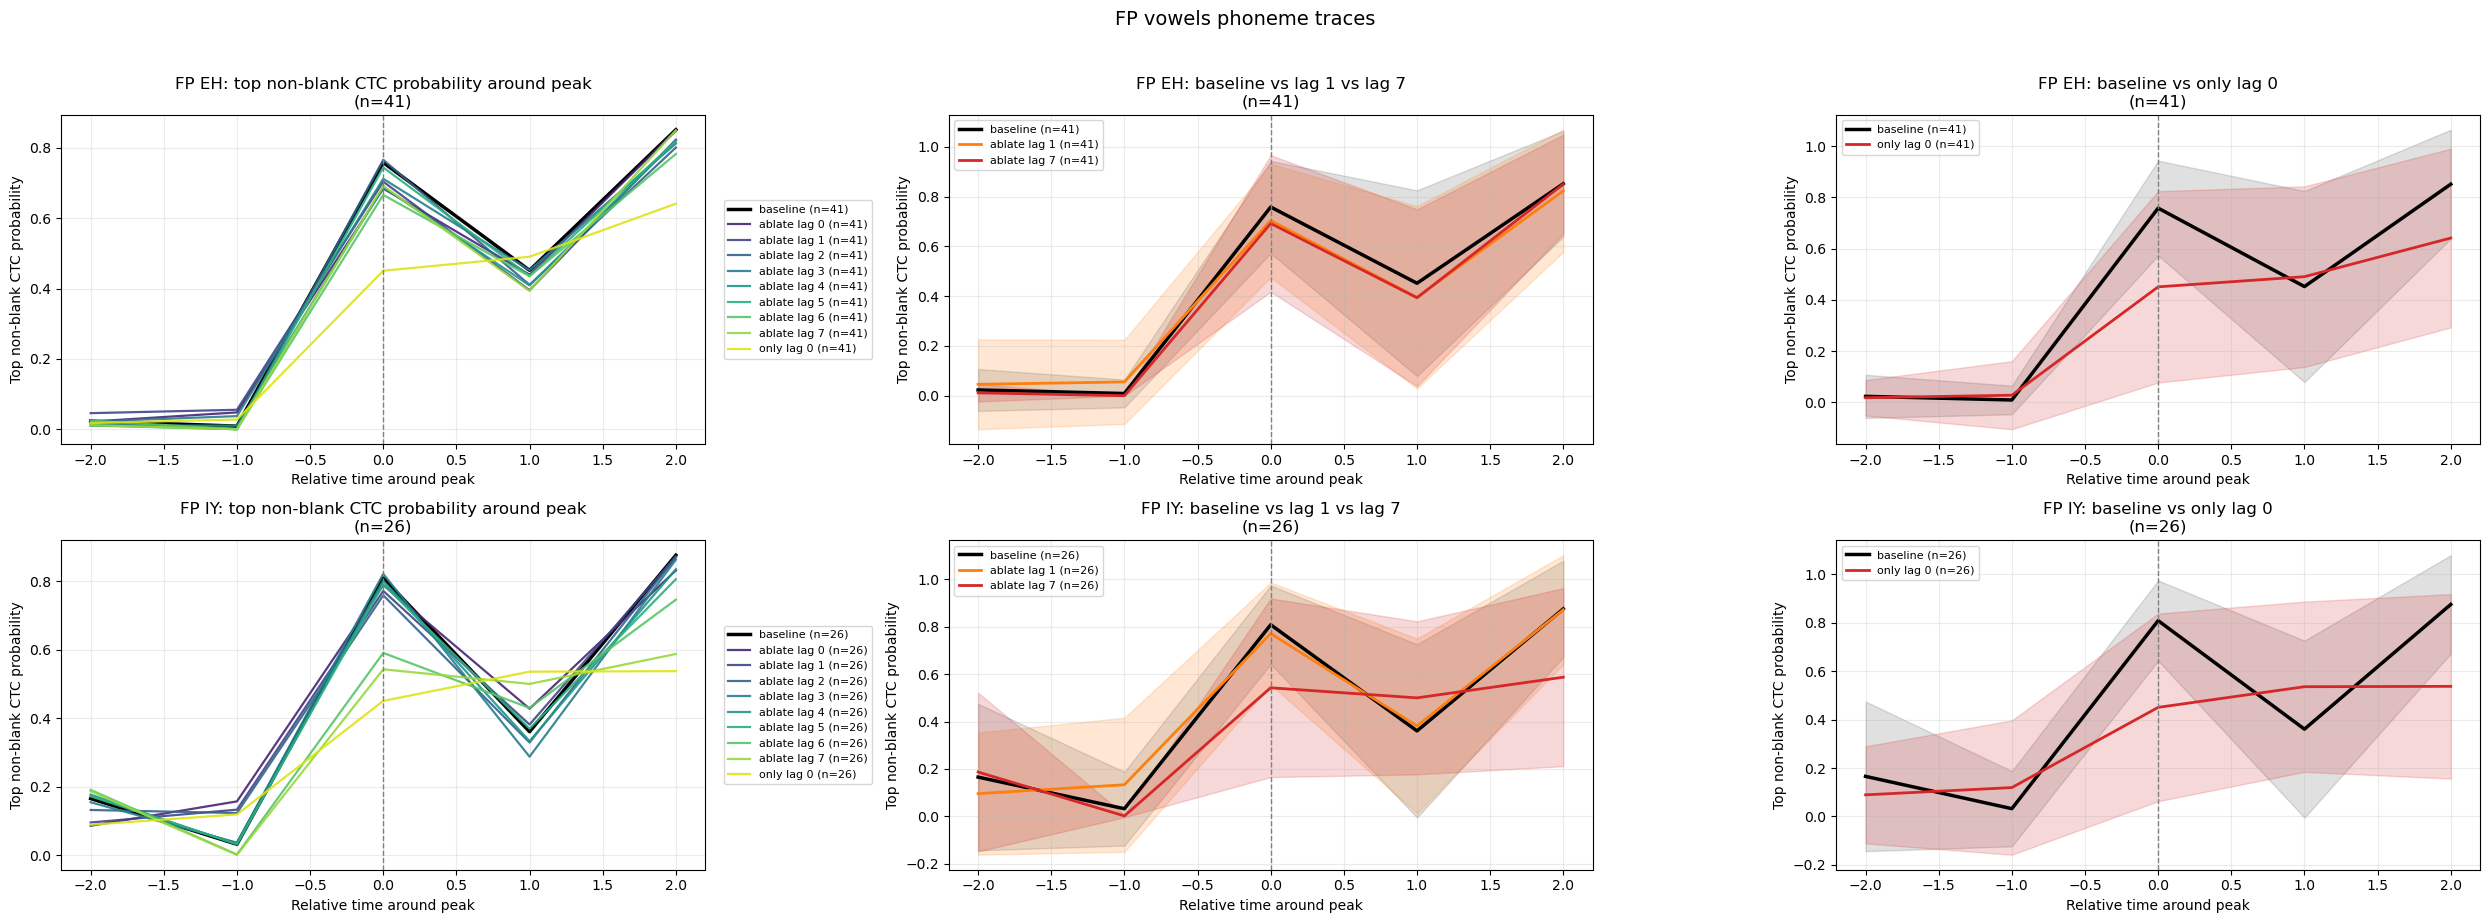

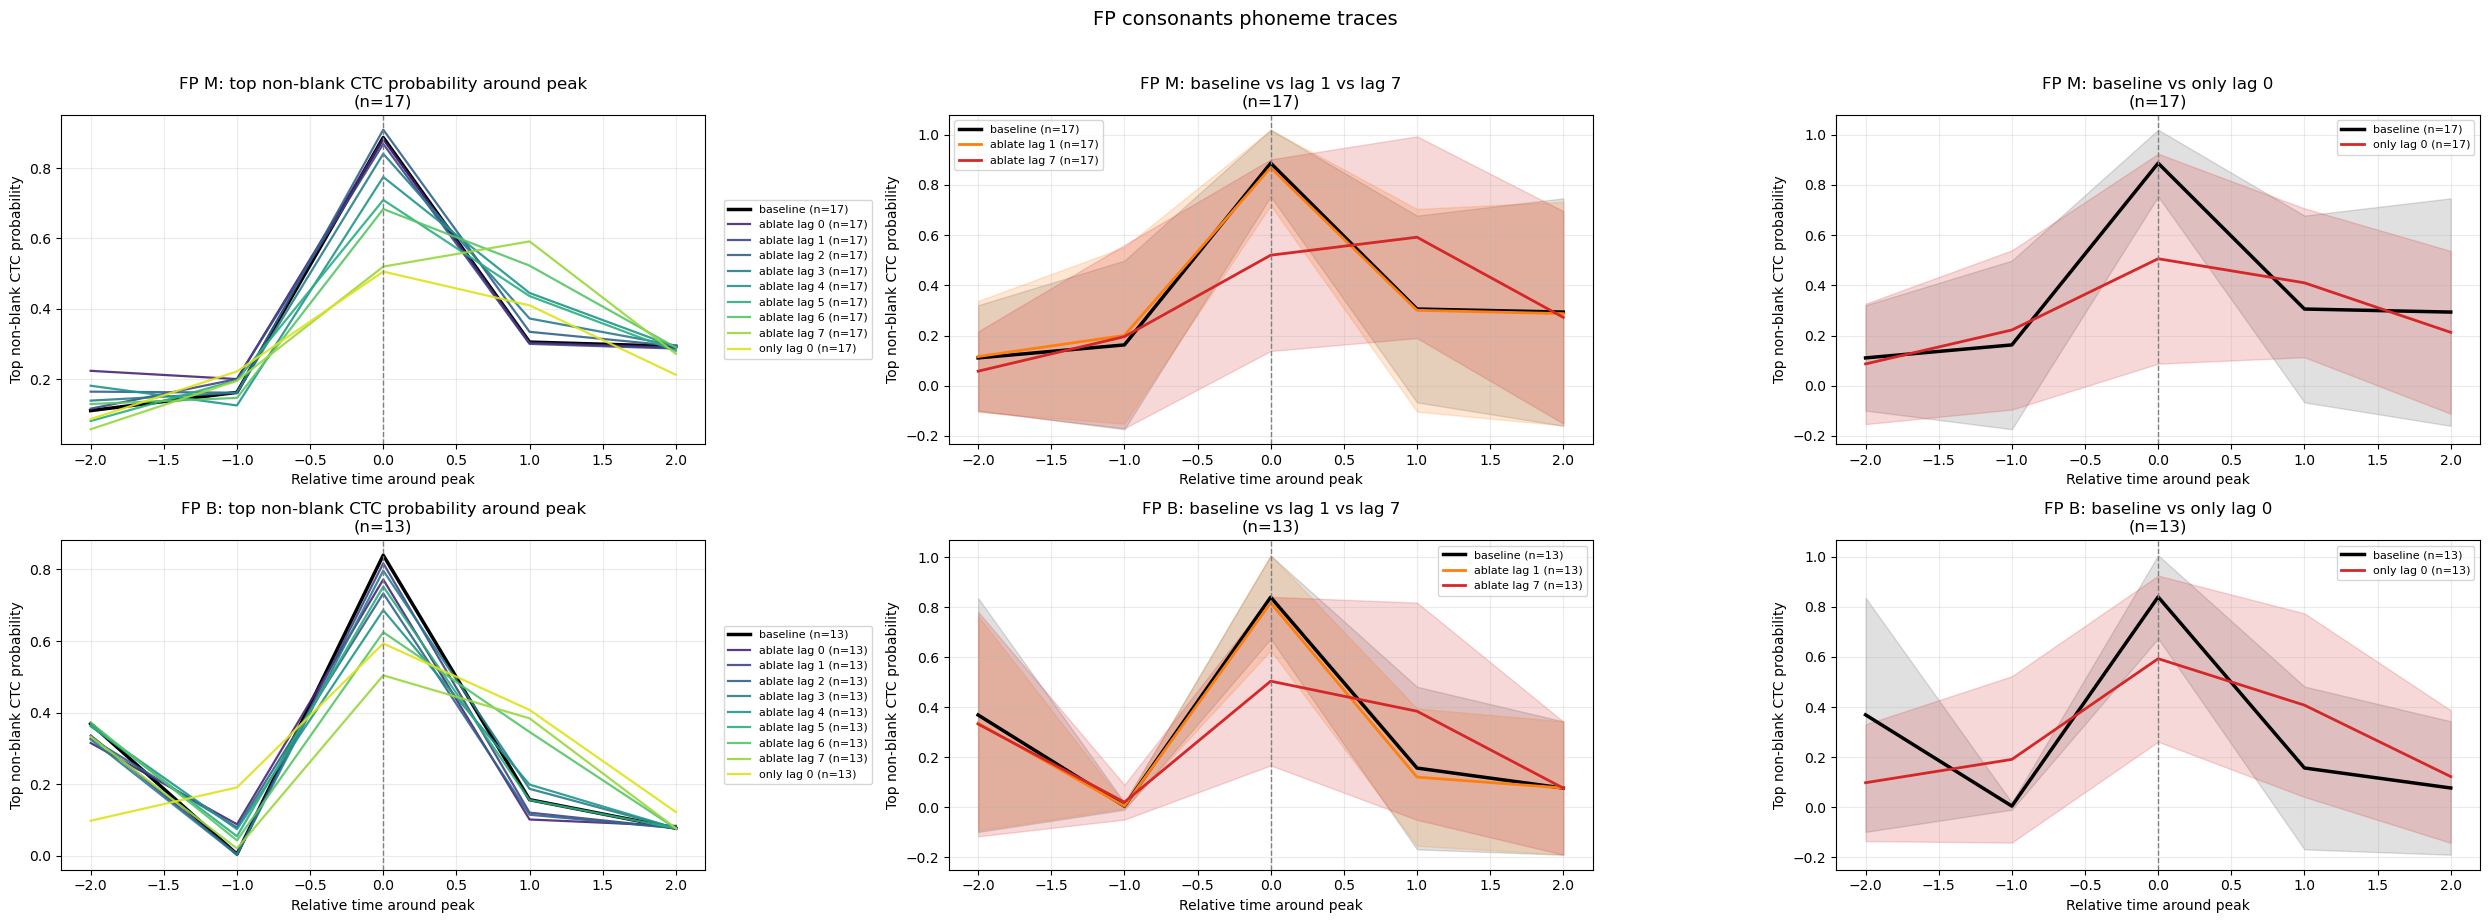

In [12]:
if not fp_peaks:
    print('[skip] no false-positive peaks were available for FP trace plots')
else:
    fp_selected = select_top_phoneme_groups(fp_peaks, per_category_limit=2)
    total_selected = sum(len(items) for items in fp_selected.values())

    if total_selected == 0:
        print('[skip] no false-positive phoneme groups passed the minimum sample threshold')
    else:
        print('Selected FP phoneme trace groups:')
        for category in ['vowels', 'consonants']:
            if not fp_selected[category]:
                print(f'  [skip] {category}: no phonemes met the threshold')
                continue
            for phoneme_label, group_peaks in fp_selected[category]:
                print(f'  {category}: {phoneme_label} (n={len(group_peaks)})')

        for category in ['vowels', 'consonants']:
            entries = fp_selected[category]
            if not entries:
                continue
            fig, axes = plt.subplots(len(entries), 3, figsize=(25, 4.5 * len(entries)), squeeze=False)
            for row_idx, (phoneme_label, group_peaks) in enumerate(entries):
                trace_payload = collect_group_ctc_probability_traces(group_peaks)
                plot_group_ctc_probability_traces(
                    axes[row_idx, 0],
                    title=f"FP {phoneme_label}: top non-blank CTC probability around peak",
                    trace_payload=trace_payload,
                )
                plot_selected_group_ctc_probability_traces(
                    axes[row_idx, 1],
                    title=f"FP {phoneme_label}: baseline vs lag 1 vs lag 7",
                    trace_payload=trace_payload,
                )
                plot_only_lag0_traces(
                    axes[row_idx, 2],
                    title=f"FP {phoneme_label}: baseline vs only lag 0",
                    trace_payload=trace_payload,
                )
            fig.suptitle(f'FP {category} phoneme traces', y=1.02, fontsize=14)
            plt.tight_layout()
            save_figure_to_pdf(fig)
            plt.show()


## Finalize Figure PDF

This cell closes the aggregated figure PDF after all plots have been generated.


In [13]:
if 'figures_pdf' not in globals() or figures_pdf is None:
    print('[skip] no open PdfPages handle was found')
else:
    figures_pdf.close()
    figures_pdf = None
    print(f'Figure PDF saved to: {Path(FIGURES_PDF_PATH).resolve()}')


Figure PDF saved to: /home/alex/snn_for_bts/brain_to_text/model_training/evaluate_model/lag_peak_ablation_basic_analysis_figures.pdf
